# Model Selection

**Benchamarked Models (regression problem)**

- Explainable Boosting (GAM ensemble boosting)
https://interpret.ml/docs/python/api/ExplainableBoostingRegressor.html

- Random Forest (ensemble bagging)
https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html

- Extreme Gradient Boosting (ensemble boosting)
https://xgboost.readthedocs.io/en/stable/python/python_api.html

- Super Vector (kernel)
https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html#sklearn.svm.SVR

- Elastic Net (regularized linear)
https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html#sklearn.linear_model.ElasticNet

- Deep Learning (neural networks)
https://docs.fast.ai/


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
import scipy.stats as ss
import scikit_posthocs as sp

In [3]:
sns.set_theme(style="darkgrid")
sns.set_palette('tab10')

## Model selection results (from Altamira)

In [46]:
# Get model selection results
models = [(m,f"model_selection_{m}.csv") for m in ['rf','xgb','sv','en','fastai'] ]
df_selection=pd.DataFrame(columns=['Model','SP','Project','Param','MSE'])
for m,file in models:
    if os.path.exists(os.path.join('results/model_selection',file)):
        df = pd.read_csv(os.path.join('results/model_selection',file))
        if m=='fastai':
            df['Param']=df.iloc[:,2].astype(str)+"/"
        else:
            df['Param']=df.iloc[:,2].astype(str)+"/"+df.iloc[:,3].astype(str)
        df['Model']=m
        df_selection=pd.concat([df_selection,df[['Model','SP','Project','Param','MSE']]],ignore_index=True)
    else:
        print(f"File {file} not found")

C:\Users\jisma\AppData\Local\Temp\ipykernel_31424\352599429.py:12: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_selection=pd.concat([df_selection,df[['Model','SP','Project','Param','MSE']]],ignore_index=True)


In [47]:
# Get and aggregate EBM results
ebm_files = [f for f in os.listdir('results/model_selection') if f.startswith('model_selection_ebm') and f.endswith('.csv')]
for file in ebm_files:
    df = pd.read_csv(os.path.join('results/model_selection',file))
    df['Param']=df.iloc[:,2].astype(str)+"/"+df.iloc[:,3].astype(str)
    df['Model']='ebm'
    df_selection=pd.concat([df_selection,df[['Model','SP','Project','Param','MSE']]],ignore_index=True)


In [48]:
df_selection.groupby(['Model'])['Model'].count()

Model
ebm       810
en        810
fastai    360
rf        810
sv        810
xgb       810
Name: Model, dtype: int64

In [31]:
# Statistical comparison of models' performance
def model_comparison(data, significance=0.05):

  # Rank the models (percentage rank)
  rank=data.rank(axis=1,pct=True)
  avg_rank=rank.mean()

  # Friedman test
  friedman_test=ss.friedmanchisquare(*data.values.T)
  print(f"Friedman's test p-value: {friedman_test.pvalue}")
  
  # Critical difference diagram incase of rejection of null hypothesis
  if friedman_test.pvalue < significance:
    print("Reject null hypothesis that all models are equally good")
    print("Conover's test for all pairs of models...\n")
    conover_test=sp.posthoc_conover_friedman(data, p_adjust='bonferroni')
    plt.figure(figsize=(10, 2))
    plt.title("Critical difference diagram of normalized score ranks")
    sp.critical_difference_diagram(avg_rank, conover_test);

### Random Forest

In [81]:
data= (df_selection.loc[df_selection['Model']=='rf',['Project','Param','MSE']].
       pivot(index='Project',columns='Param',values='MSE'))
data

Param,100/10.0,100/5.0,100/nan,1000/10.0,1000/5.0,1000/nan,500/10.0,500/5.0,500/nan
Project,,,,,,,,,
ev10,0.005849,0.063346,0.005526,0.005575,0.061786,0.005142,0.005619,0.061718,0.005187
ev102,0.104051,0.334613,0.093709,0.101093,0.330938,0.090703,0.101321,0.330775,0.090658
ev108,0.037188,0.175563,0.033778,0.036549,0.174796,0.033154,0.036549,0.174792,0.033195
ev124,0.081271,0.281028,0.073382,0.078059,0.274467,0.069759,0.078268,0.274310,0.070030
ev131,0.091034,0.325240,0.082379,0.089198,0.325382,0.080279,0.089608,0.326384,0.080811
...,...,...,...,...,...,...,...,...,...
ev854,1.718899,2.797047,1.518796,1.672312,2.784516,1.471439,1.676747,2.788204,1.474784
ev862,1.726461,2.846775,1.546249,1.717083,2.842148,1.527715,1.710308,2.840270,1.520110
ev864,1.801635,2.839981,1.604091,1.778811,2.832990,1.578623,1.782074,2.835399,1.583907


Friedman's test p-value: 1.1242514258500974e-143
Reject null hypothesis that all models are equally good
Conover's test for all pairs of models...



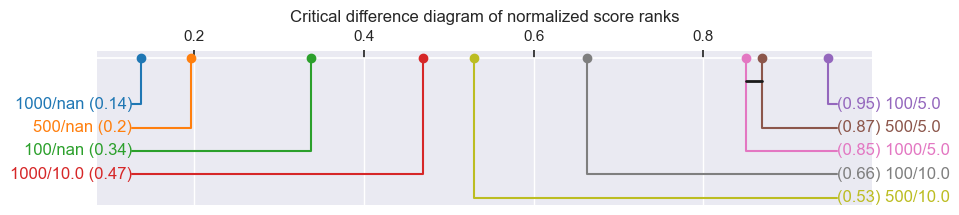

In [22]:
model_comparison(data)

### XGBoost

In [84]:
data= (df_selection.loc[df_selection['Model']=='xgb',['Project','Param','MSE']].
       pivot(index='Project',columns='Param',values='MSE'))

Friedman's test p-value: 8.226331503166467e-120
Reject null hypothesis that all models are equally good
Conover's test for all pairs of models...



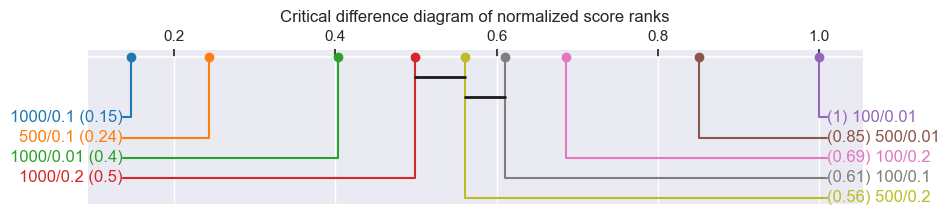

In [24]:
model_comparison(data)

### Super Vector

In [86]:
data= (df_selection.loc[df_selection['Model']=='sv',['Project','Param','MSE']].
       pivot(index='Project',columns='Param',values='MSE'))

Friedman's test p-value: 4.693721245923491e-146
Reject null hypothesis that all models are equally good
Conover's test for all pairs of models...



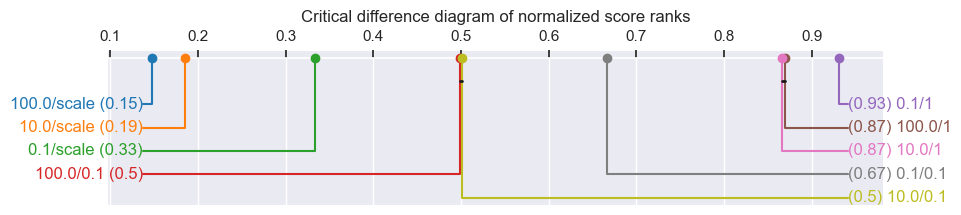

In [33]:
model_comparison(data)

### Elastic Net

In [89]:
data= (df_selection.loc[df_selection['Model']=='en',['Project','Param','MSE']].
       pivot(index='Project',columns='Param',values='MSE'))

Friedman's test p-value: 8.192131637540022e-150
Reject null hypothesis that all models are equally good
Conover's test for all pairs of models...



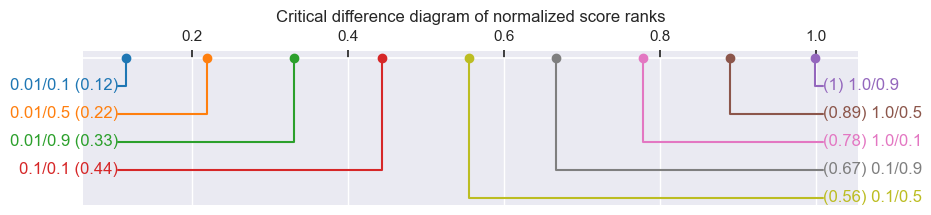

In [35]:
model_comparison(data)

### EBM

In [91]:
data= (df_selection.loc[df_selection['Model']=='ebm',['Project','Param','MSE']].
       pivot(index='Project',columns='Param',values='MSE'))

Friedman's test p-value: 5.260131050493384e-62
Reject null hypothesis that all models are equally good
Conover's test for all pairs of models...



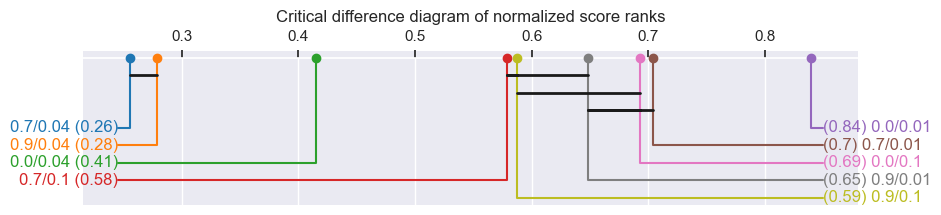

In [43]:
model_comparison(data)

### Deep Learning

In [93]:
data= (df_selection.loc[df_selection['Model']=='fastai',['Project','Param','MSE']].
       pivot(index='Project',columns='Param',values='MSE'))

In [95]:
data

Param,"[100, 50]/","[200, 100]/","[300, 200]/","[400, 300]/"
Project,,,,
ev10,0.015190,0.182597,0.005589,0.020114
ev102,0.105629,0.016954,0.169354,0.086376
ev108,0.176429,0.172961,0.056142,0.044820
ev124,0.168895,0.729973,0.211412,0.266788
ev131,0.121245,0.045239,0.012841,0.021262
...,...,...,...,...
ev854,0.937112,0.310664,0.237558,0.809638
ev862,0.431266,0.395391,0.327319,0.158854
ev864,2.537585,0.354418,2.521415,0.697695


Friedman's test p-value: 0.04601170568923136
Reject null hypothesis that all models are equally good
Conover's test for all pairs of models...



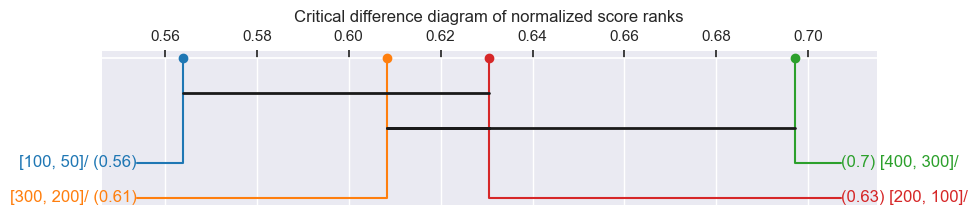

In [50]:
model_comparison(data)

## Model benchmarking (based on the model selection dataset)
Using the best parameterization of each model

In [96]:
best_params={'rf':'1000/nan',
             'xgb':'1000/0.1',
             'sv':'100.0/scale',
             'en':'0.01/0.1',
             'ebm':'0.7/0.04',
             'fastai':'[200, 100]/'}

In [100]:
model='rf'
data=df_selection.loc[(df_selection['Model']==model) & (df_selection['Param']==best_params[model]),['Project','MSE']]
data.set_index('Project',inplace=True)
data.rename(columns={'MSE':'RF'},inplace=True)
for model in ['xgb','sv','en','ebm','fastai']:
    data2=df_selection.loc[(df_selection['Model']==model) & (df_selection['Param']==best_params[model]),['Project','MSE']]
    data2.set_index('Project',inplace=True)
    data2.rename(columns={'MSE':model.upper()},inplace=True)
    data=pd.concat([data,data2],axis=1)
data

,RF,XGB,SV,EN,EBM,FASTAI
Project,,,,,,
ev102,0.090703,0.020355,0.037098,0.000311,0.000201,0.016954
ev108,0.033154,0.008089,0.027275,0.000135,0.000033,0.172961
ev124,0.069759,0.015457,0.032355,0.000163,0.000078,0.729973
ev131,0.080279,0.018568,0.038313,0.000167,0.000038,0.045239
ev138,0.130200,0.029092,0.044266,0.000211,0.000116,0.669801
...,...,...,...,...,...,...
ev854,1.471439,0.433765,0.081973,0.000549,0.000272,0.310664
ev862,1.527715,0.441527,0.093883,0.000598,0.000212,0.395391
ev864,1.578623,0.452603,0.091400,0.000642,0.000236,0.354418


Friedman's test p-value: 1.9723587121436214e-66
Reject null hypothesis that all models are equally good
Conover's test for all pairs of models...



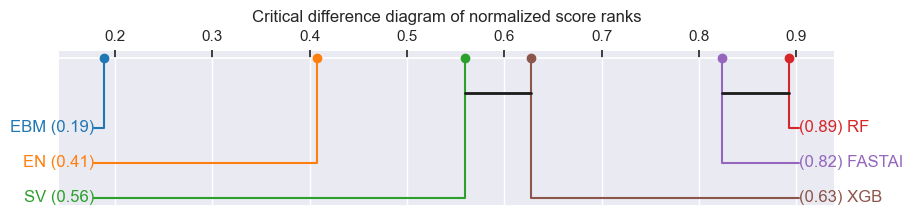

In [101]:
model_comparison(data)